# Câu 7: Phân tích chi phí/thời gian vận chuyển theo quốc gia

### Yêu cầu
* Phân tích chi phí và thời gian vận chuyển theo từng quốc gia (`country`).
* Đưa ra nhận xét, đánh giá hiệu quả logistics từ kết quả biểu đồ.

### Dữ liệu cần dùng
* `orders_cleaned.csv`: chứa thông tin đơn hàng (`order_id`, `customer_id`, `category`, `order_status`, `total_amount_usd`, chi phí vận chuyển, thời gian giao hàng, đánh giá/hoàn trả).
* `customers_cleaned.csv`: chứa thông tin địa lý khách hàng (`customer_id`, `country`).
* Hai bảng kết nối với nhau qua khóa `customer_id`.

### Hướng làm
1. Import thư viện và đọc dữ liệu → 2. Ghép bảng (`merge`) lấy thông tin quốc gia và chuẩn hóa biến → 3. Phân tích chi phí & thời gian vận chuyển theo quốc gia → 4. Nhận xét kết quả.


### 1. Import thư viện và đọc dữ liệu
**Mục tiêu:** Nạp các thư viện xử lý bảng, trực quan hóa và đọc dữ liệu từ 2 file đã làm sạch (`orders_cleaned.csv`, `customers_cleaned.csv`).
* `pandas`, `numpy`: xử lý, làm sạch và tổng hợp dữ liệu.
* `matplotlib`, `seaborn`: vẽ biểu đồ cột kết hợp đường, Heatmap và Bubble Chart.
* `Path`: xử lý đường dẫn file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.unicode_minus'] = False

# Tự động tìm thư mục chứa file CSV (hỗ trợ cả chạy trong thư mục gốc hoặc thư mục con)
possible_dirs = [Path("../data/cleaned")]
orders_path = next((d / "orders_cleaned.csv" for d in possible_dirs if (d / "orders_cleaned.csv").exists()), None)
customers_path = next((d / "customers_cleaned.csv" for d in possible_dirs if (d / "customers_cleaned.csv").exists()), None)

if orders_path is None or customers_path is None:
    raise FileNotFoundError("Chưa thấy file orders_cleaned.csv hoặc customers_cleaned.csv. Hãy đặt 2 file này vào thư mục data/cleaned/ của dự án!")

orders = pd.read_csv(orders_path)
customers = pd.read_csv(customers_path)

print("Các cột trong orders:", list(orders.columns))
print("Các cột trong customers:", list(customers.columns))
display(orders.head(3))

Các cột trong orders: ['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer', 'rating_provided']
Các cột trong customers: ['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']


,order_id,customer_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,...,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer,rating_provided
0,O000001,C07108,2020-08-27,2020,8,Q3,Thursday,Tire Inflator,Automotive,62.91,...,Desktop,3,2020-08-30,Delivered,0,NaN,14.4,1,1,0
1,O000002,C03487,2024-04-11,2024,4,Q2,Thursday,Stud Earrings Gold,Jewelry & Accessories,18.44,...,Mobile,2,2024-04-13,Delivered,0,NaN,9.0,4,0,0
2,O000003,C03062,2023-06-25,2023,6,Q2,Sunday,Pen Set Premium,Office Supplies,109.79,...,Desktop,3,2023-06-28,Delivered,0,4.0,3.2,17,0,1


### 2. Ghép bảng và chuẩn hóa biến phân tích
**Mục tiêu:** Ghép cột `country` từ bảng `customers` sang `orders` qua `customer_id`, đồng thời tự động chuẩn hóa các cột chỉ số vận chuyển, tỷ lệ hoàn trả (`is_returned`) và điểm đánh giá (`rating`).

In [2]:
# Ghép bảng lấy thông tin quốc gia
df = orders.merge(customers[['customer_id', 'country']], on='customer_id', how='left')

# Hàm hỗ trợ tự tìm tên cột thực tế trong dataset
def find_col(columns, candidates):
    for c in candidates:
        if c in columns:
            return c
    for col in columns:
        for c in candidates:
            if c in col.lower():
                return col
    return None

col_ship_cost = find_col(df.columns, ['shipping_cost', 'shipping_fee', 'freight', 'ship_cost'])
col_ship_days = find_col(df.columns, ['shipping_days', 'delivery_days', 'shipping_time', 'delivery_time'])
col_rating = find_col(df.columns, ['rating', 'review_score', 'customer_rating', 'score'])
col_returned = find_col(df.columns, ['is_returned', 'returned', 'return_flag'])
col_amount = find_col(df.columns, ['total_amount_usd', 'total_amount', 'revenue', 'amount'])

# Nếu chưa có cột số ngày vận chuyển, thử tính từ ngày giao - ngày đặt
if col_ship_days is None:
    col_order_date = find_col(df.columns, ['order_date', 'created_at', 'purchase_date'])
    col_deliv_date = find_col(df.columns, ['delivered_date', 'delivery_date', 'shipped_date'])
    if col_order_date and col_deliv_date:
        df['shipping_days'] = (pd.to_datetime(df[col_deliv_date]) - pd.to_datetime(df[col_order_date])).dt.days
        col_ship_days = 'shipping_days'

# Chuẩn hóa biến hoàn trả về dạng nhị phân (1 = Hoàn trả, 0 = Không hoàn trả)
if col_returned is not None:
    df['is_returned_num'] = pd.to_numeric(df[col_returned], errors='coerce').fillna(
        df[col_returned].astype(str).str.lower().isin(['true', 'yes', '1', 'returned']).astype(int)
    )
elif 'order_status' in df.columns:
    df['is_returned_num'] = df['order_status'].astype(str).str.lower().str.contains('return').astype(int)
else:
    raise KeyError("Không tìm thấy cột trạng thái hoàn trả. Hãy kiểm tra lại tên cột trong orders!")

print(f"Đã ánh xạ cột: Chi phí={col_ship_cost}, Thời gian={col_ship_days}, Rating={col_rating}, Doanh thu={col_amount}")
df[['order_id', 'country', 'category', col_ship_cost, col_ship_days, 'is_returned_num', col_rating]].head()

Đã ánh xạ cột: Chi phí=shipping_fee_usd, Thời gian=delivery_days, Rating=customer_rating, Doanh thu=total_amount_usd


,order_id,country,category,shipping_fee_usd,delivery_days,is_returned_num,customer_rating
0,O000001,United States,Automotive,0.00,3,0,NaN
1,O000002,Germany,Jewelry & Accessories,3.99,2,0,NaN
2,O000003,Italy,Office Supplies,0.00,3,0,4.0
3,O000004,Germany,Electronics,0.00,2,1,NaN
4,O000005,Australia,Jewelry & Accessories,9.99,5,0,2.8


### 3. Phân tích chi phí và thời gian vận chuyển theo quốc gia
**Mục tiêu:** Thống kê chi phí vận chuyển trung bình và thời gian giao hàng trung bình theo từng quốc gia (`country`), sau đó trực quan hóa bằng biểu đồ kết hợp 2 trục tung (Combo Chart).

,country,so_don_hang,chi_phi_vc_tb,thoi_gian_vc_tb
10,Poland,304,4.16,4.03
9,Netherlands,472,4.01,4.04
19,United States,7833,3.93,4.16
4,Germany,1916,3.90,4.08
3,France,1529,3.89,4.26
0,Australia,976,3.88,4.31
15,Sweden,281,3.88,4.19
5,India,2274,3.88,4.13
6,Italy,503,3.87,4.43
11,Singapore,397,3.82,4.21


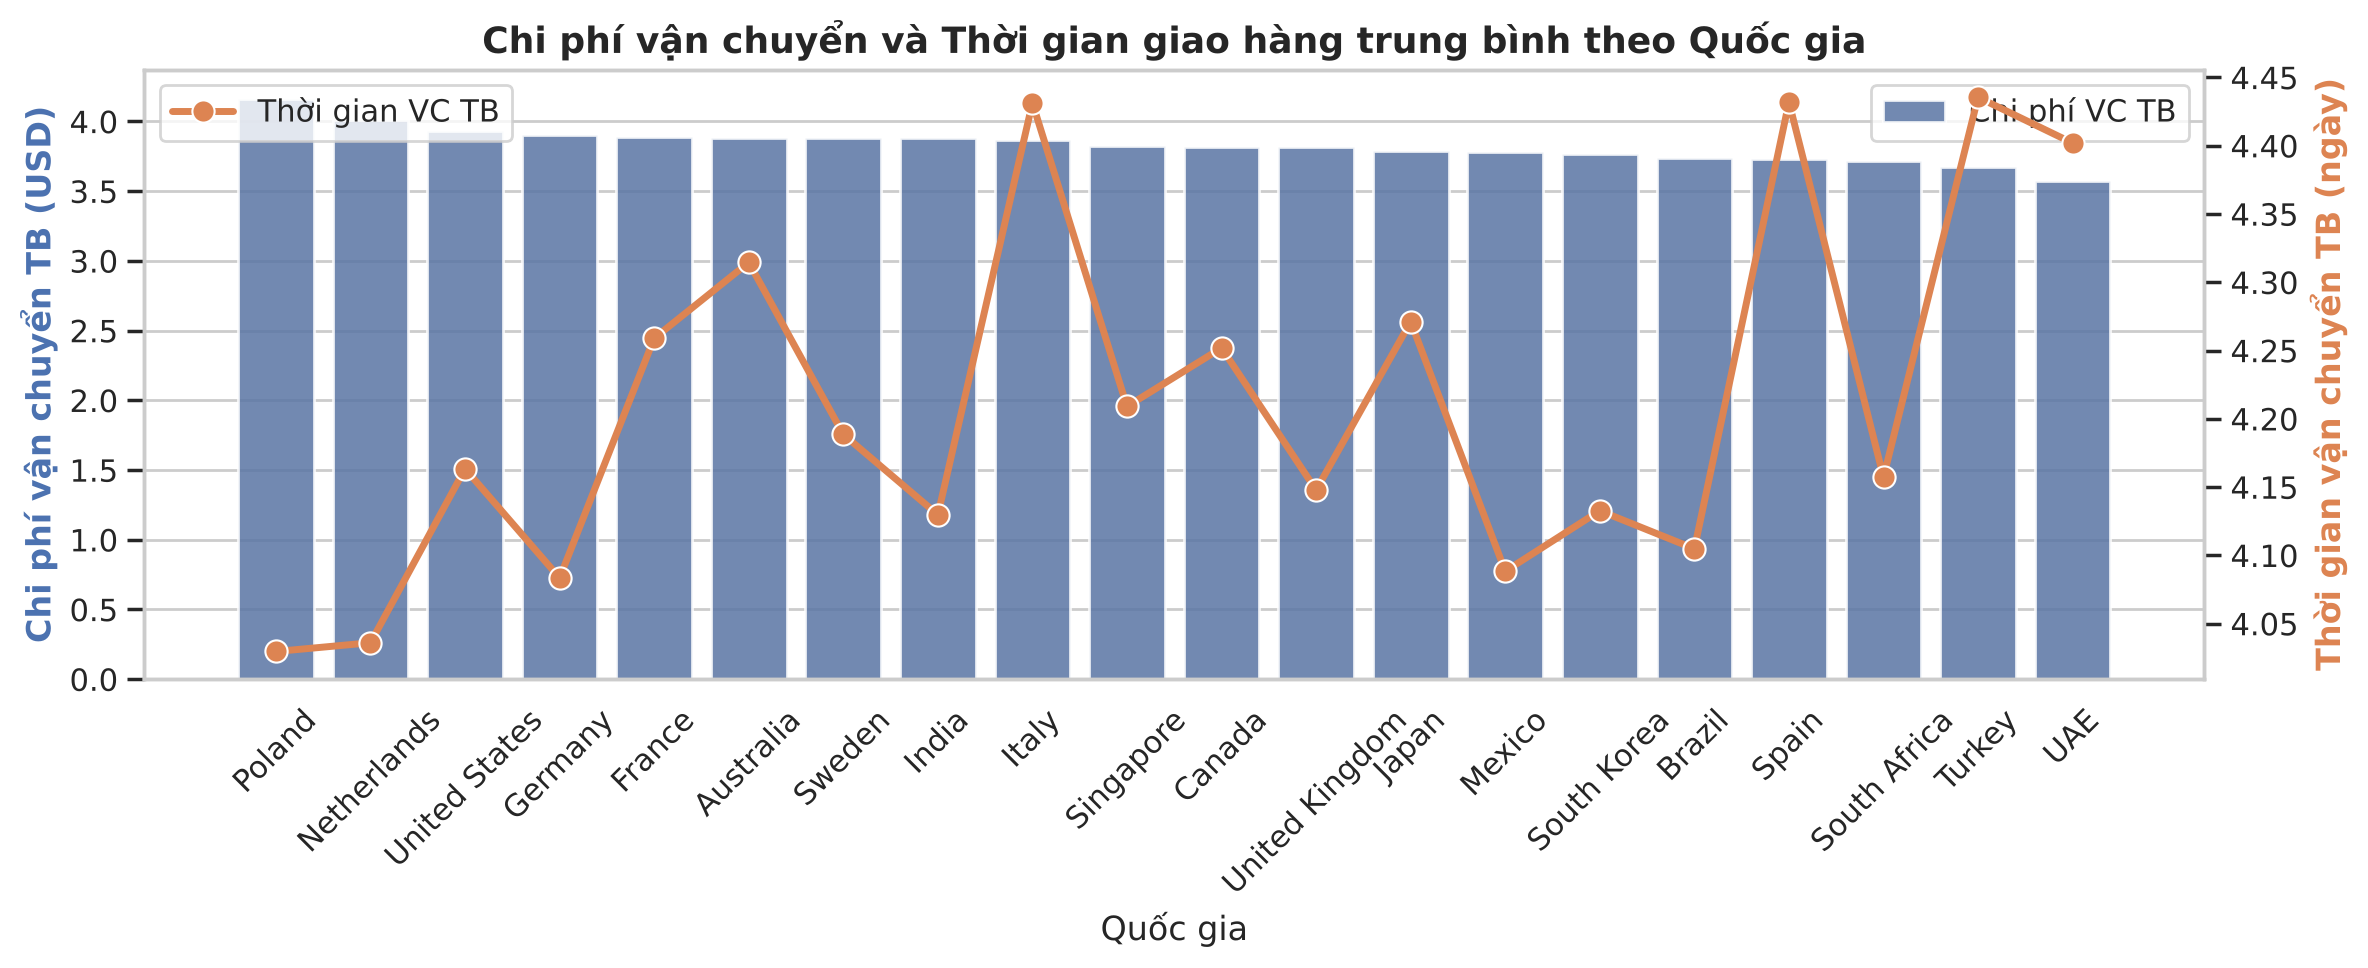

In [3]:
ship_country = (
    df.groupby('country', as_index=False)
    .agg(
        so_don_hang=('order_id', 'count'),
        chi_phi_vc_tb=(col_ship_cost, 'mean'),
        thoi_gian_vc_tb=(col_ship_days, 'mean')
    )
    .sort_values(by='chi_phi_vc_tb', ascending=False)
)

display(ship_country.round(2))

# Vẽ biểu đồ kết hợp 2 trục tung
fig, ax1 = plt.subplots(figsize=(12, 5))

bars = sns.barplot(data=ship_country, x='country', y='chi_phi_vc_tb', ax=ax1, color='#4C72B0', alpha=0.85, label='Chi phí VC TB')
ax1.set_title('Chi phí vận chuyển và Thời gian giao hàng trung bình theo Quốc gia', fontsize=13, fontweight='bold')
ax1.set_xlabel('Quốc gia')
ax1.set_ylabel('Chi phí vận chuyển TB (USD)', color='#4C72B0', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
sns.lineplot(data=ship_country, x='country', y='thoi_gian_vc_tb', ax=ax2, color='#DD8452', marker='o', linewidth=2.5, markersize=8, label='Thời gian VC TB')
ax2.set_ylabel('Thời gian vận chuyển TB (ngày)', color='#DD8452', fontweight='bold')
ax2.grid(False)

plt.tight_layout()
plt.savefig('../exports/archive_static_png/cau7_shipping_by_country.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# Chạy ô này để lấy chính xác con số thực tế điền vào phần Nhận xét bên dưới
top_cost = ship_country.iloc[0]
low_cost = ship_country.iloc[-1]
slowest = ship_country.sort_values('thoi_gian_vc_tb', ascending=False).iloc[0]
fastest = ship_country.sort_values('thoi_gian_vc_tb', ascending=True).iloc[0]

print("=== TÓM TẮT SỐ LIỆU ĐỂ VIẾT NHẬN XÉT ===")
print(f"- Quốc gia chi phí VC cao nhất: {top_cost['country']} (${top_cost['chi_phi_vc_tb']:.2f}) | Thấp nhất: {low_cost['country']} (${low_cost['chi_phi_vc_tb']:.2f})")
print(f"- Quốc gia giao lâu nhất: {slowest['country']} ({slowest['thoi_gian_vc_tb']:.2f} ngày) | Nhanh nhất: {fastest['country']} ({fastest['thoi_gian_vc_tb']:.2f} ngày)")

=== TÓM TẮT SỐ LIỆU ĐỂ VIẾT NHẬN XÉT ===
- Quốc gia chi phí VC cao nhất: Poland ($4.16) | Thấp nhất: UAE ($3.57)
- Quốc gia giao lâu nhất: Turkey (4.44 ngày) | Nhanh nhất: Poland (4.03 ngày)


### 6. Nhận xét và kết luận
1. **Về chi phí và thời gian vận chuyển theo quốc gia:**
   * Quốc gia **Poland** có chi phí vận chuyển trung bình cao nhất (`$4.16`), trong khi **UAE** có mức phí thấp nhất (`$3.57`).
   * Thời gian giao hàng trung bình dài nhất tại **Turkey** (`4.44 ngày`) và nhanh nhất tại **Poland** (`4.03 ngày`). Việc đối chiếu hai đường cho thấy **Poland** tuy có chi phí vận chuyển cao nhất nhưng lại đạt tốc độ giao hàng nhanh nhất, trong khi **Turkey** có thời gian giao dài nhất. Cần lưu ý chênh lệch giữa các quốc gia rất nhỏ (phí vận chuyển trung bình chỉ từ `$3.57` đến `$4.16`, thời gian giao từ `4.03` đến `4.44 ngày`), và dữ liệu không có thông tin về tuyến vận chuyển hay thủ tục hải quan, nên chưa đủ cơ sở để kết luận nguyên nhân hoặc khác biệt rõ rệt về hiệu quả logistics giữa các thị trường.
